In [1]:
import numpy as np
import pandas as pd

In [2]:
from pathlib import Path

In [3]:
data_dir = Path(
    "/Users/sahil/CircuitCost/CircuitCost/ML4Accel-Dataset/"
    "fpga_ml_dataset/HLS_dataset/polybench/"
    "gemm/xczu9eg-ffvb1156-2-i"
)

hls = pd.read_csv(data_dir / "post_hls_info.csv")
impl = pd.read_csv(data_dir / "post_implementation_info.csv")
hls.head()

,prj,clk_target(ns),clk_estimated(ns),clk_uncertainty(ns),bram,dsp,ff,lut,c_num_arith,c_num_logic,rtl_num_arith,rtl_num_logic,data_input_port(numxbits),data_output_port(numxbits)
0,io1_l2n1n1_l4n1n1,10.0,8.419,1.25,32,5,758,1239,22,9,19,9,5x32,1x32
1,io1_l2n1n1_l4n1p1,10.0,8.419,1.25,32,5,933,1356,23,9,20,9,5x32,1x32
2,io1_l2n1n1_l4p1n1,10.0,9.298,1.25,32,5,4578,3914,146,71,17,71,5x32,1x32
3,io1_l2n1p1_l4n1n1,10.0,8.419,1.25,32,5,845,1416,24,12,21,12,5x32,1x32
4,io1_l2n1p1_l4n1p1,10.0,8.419,1.25,32,5,1020,1519,25,12,22,12,5x32,1x32


In [4]:
#Preparing features from HLS table
feature_columns = [
    "clk_target(ns)",
    "clk_estimated(ns)",
    "clk_uncertainty(ns)",
    "bram",
    "dsp",
    "ff",
    "lut",
    "c_num_arith",
    "c_num_logic",
    "rtl_num_arith",
    "rtl_num_logic"
]

In [5]:
#Defining X and y
X = hls[feature_columns].copy()
y = impl["Total LUTs"].copy()
X.head()

,clk_target(ns),clk_estimated(ns),clk_uncertainty(ns),bram,dsp,ff,lut,c_num_arith,c_num_logic,rtl_num_arith,rtl_num_logic
0,10.0,8.419,1.25,32,5,758,1239,22,9,19,9
1,10.0,8.419,1.25,32,5,933,1356,23,9,20,9
2,10.0,9.298,1.25,32,5,4578,3914,146,71,17,71
3,10.0,8.419,1.25,32,5,845,1416,24,12,21,12
4,10.0,8.419,1.25,32,5,1020,1519,25,12,22,12


In [6]:
y.head()

0     645
1     656
2    4131
3     813
4     833
Name: Total LUTs, dtype: int64

In [7]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
#Splitting the Dataset into Training,Validation and Testing
from sklearn.model_selection import train_test_split

#First Split : 70% Training, 30% remaining
X_train, X_remaining, y_train, y_remaining = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)


In [9]:
#Second split: divide the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=42
)

In [10]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (371, 11) (371,)
Validation: (80, 11) (80,)
Testing: (80, 11) (80,)


In [11]:
#Normalizing the values of dataset
#xscaled = x-training mean/ training standard deviation

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [12]:
print("Training means:", X_train_scaled.mean(axis=0))
print("Training standard deviations:", X_train_scaled.std(axis=0))

Training means: [ 0.00000000e+00  5.43919507e-15  0.00000000e+00 -9.81544884e-17
 -1.19700596e-18  4.78802383e-18  3.35161668e-17  2.39401191e-18
 -7.18203574e-17 -1.04139518e-16 -7.18203574e-17]
Training standard deviations: [0. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1.]


In [13]:
#Checking the scaled values of training, validation and test dataset

print("Training Set Values:",X_train_scaled[:5])
print("Validation Set Values:",X_val_scaled[:5])
print("Test Set Values:",X_test_scaled[:5])

Training Set Values: [[ 0.          0.82623687  0.          0.02109145  0.32020436 -0.06756909
   0.32212357  0.40429841  1.10444938  0.30571932  1.10444938]
 [ 0.          1.53724386  0.         -0.70120974  0.39959564  0.02560379
   0.29072785  0.08170658  3.26809244  0.40656864  3.26809244]
 [ 0.         -0.04600219  0.          1.94722798  3.52231933  1.3838275
   2.12778324  0.62198233 -0.32355503  3.39843175 -0.32355503]
 [ 0.          0.01479023  0.          1.94722798  0.34666812 -0.12817309
   0.56848323 -0.4270968  -0.45337361  0.23848644 -0.45337361]
 [ 0.          1.50552608  0.         -0.64101798  0.18788556 -0.04772243
  -0.0318429   0.11842435 -0.23700931  0.54103439 -0.23700931]]
Validation Set Values: [[ 0.          0.76544445  0.          2.91029624  0.58484196  3.17992674
   3.0815141   2.74636756 -0.06391786  0.44018508 -0.06391786]
 [ 0.         -1.43365523  0.         -0.70120974 -0.64572288 -0.70460511
  -0.86604531 -0.76804751 -0.88610223 -0.80362319 -0.8861022

In [14]:
#Establishing a baseline
#Baseline 1: HLS estimate , Prediction rule = Predicted implementation LUTs=HLS lut
#Baseline 2: Linear regression, Prediction rule = Weighted combination of selected HLS feature

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

pred_hls_val = X_val["lut"].to_numpy()

In [15]:
#Train Linear regression

linear_model = LinearRegression() #Creates an unfitted model
linear_model.fit(X_train_scaled, y_train) #Learns a coefficient for each feature and an intercept from the training example
pred_linear_val = linear_model.predict(X_val_scaled) #applies the learned relationship to validation inputs

In [16]:
#Evaluate both baselines consistently

def evaluate_predictions(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true,y_pred),
        "RMSE": mean_squared_error(y_true,y_pred) ** 0.5,
        "R2": r2_score(y_true,y_pred)
    }

In [17]:
#Check the result
results = pd.DataFrame({
    "HLS estimate" : evaluate_predictions(y_val, pred_hls_val),
    "Linear Regression" : evaluate_predictions(y_val,pred_linear_val),
}).T

display(results)

,MAE,RMSE,R2
HLS estimate,5758.975000,9836.975108,0.384620
Linear Regression,936.894108,1595.877056,0.983804


In [18]:
comparison = pd.DataFrame({
    "Actual LUTs": y_val,
    "HLS prediction": pred_hls_val,
    "Linear prediction": pred_linear_val,
})

display(comparison.head())

,Actual LUTs,HLS prediction,Linear prediction
524,47722,64484,49496.295153
0,645,1239,1485.024557
9,727,1508,1488.372303
228,24354,27558,23359.848428
57,7420,15039,10985.977862


In [19]:
import sys
print(sys.executable)

/Users/sahil/venvs/ann/bin/python


In [20]:
%pip install -e "/Users/sahil/CircuitCost/CircuitCost"

Obtaining file:///Users/sahil/CircuitCost/CircuitCost
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for circuitcost (pyproject.toml) ... done
  Created wheel for circuitcost: filename=circuitcost-0.1.0-0.editable-py3-none-any.whl size=5973 sha256=89c4fe43309e95d835354f61e12e693d07bfb3edeb1ab0d70d05227d976fc601
  Stored in directory: /private/var/folders/s8/_c97b0k12817pts24pvmjr480000gn/T/pip-ephem-wheel-cache-tqwo4inu/wheels/7f/8c/7d/cafbcc6554a2e8ecd049a1057386149b17bf8a574b3b6496f0
Successfully built circuitcost
  Attempting uninstall: circuitcost
    Found existing installation: circuitcost 0.1.0
    Uninstalling circuitcost-0.1.0:
      Successfully uninstalled circuitcost-0.1.0

[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may 

In [22]:
#using custom MLP
from circuitcost.models import NeuralNetworks
from circuitcost.train import train_model

np.random.seed(42)

model = NeuralNetworks(n_inputs=X_train_scaled.shape[1])

history = train_model(
    model,
    X_train_scaled,
    y_train,
    X_val_scaled,
    y_val,
    epochs=1000,
    learning_rate=0.000001,
)


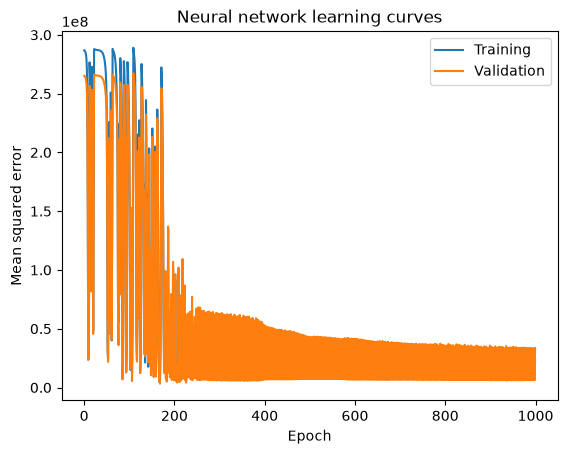

In [ ]:
#Plotting the learining curves
import matplotlib.pyplot as plt

plt.plot(history["train_loss"], label="Training")
plt.plot(history["val_loss"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Neural network learning curves")
plt.legend()
plt.show()

In [26]:
#Generate validation predictions

pred_nn_val = model.forward(X_val_scaled).ravel()

print("Predictions are finite:", np.isfinite(pred_nn_val).all())
print("Negative predictions:", np.sum(pred_nn_val < 0))

Predictions are finite: True
Negative predictions: 0


In [27]:
#Calculate same metrics as baseline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

mae_nn = mean_absolute_error(y_val, pred_nn_val)
rmse_nn = np.sqrt(mean_squared_error(y_val, pred_nn_val))
r2_nn = r2_score(y_val, pred_nn_val)

print(f"Neural network MAE:  {mae_nn:.2f} LUTs")
print(f"Neural network RMSE: {rmse_nn:.2f} LUTs")
print(f"Neural network R²:   {r2_nn:.4f}")

Neural network MAE:  3044.42 LUTs
Neural network RMSE: 5796.02 LUTs
Neural network R²:   0.7864


In [28]:
#inspect indivual predictions


comparison = pd.DataFrame({
    "Actual LUTs": np.asarray(y_val),
    "Predicted LUTs": pred_nn_val,
})

comparison["Absolute error"] = (
    comparison["Predicted LUTs"] - comparison["Actual LUTs"]
).abs()

display(comparison.sort_values("Absolute error", ascending=False).head(10))

,Actual LUTs,Predicted LUTs,Absolute error
40,59208,30970.446548,28237.553452
50,50293,31562.069853,18730.930147
9,45776,27622.693893,18153.306107
35,32316,17051.344818,15264.655182
0,47722,32763.119096,14958.880904
54,32236,18161.031624,14074.968376
58,33175,22555.487588,10619.512412
22,35603,25213.488456,10389.511544
60,24276,17923.113772,6352.886228
41,26548,20310.487522,6237.512478


In [29]:
# Use the already-trained models
pred_linear_val = linear_model.predict(X_val_scaled)
pred_nn_val = model.forward(X_val_scaled).ravel()

results = pd.DataFrame({
    "HLS estimate": evaluate_predictions(
        y_val, X_val["lut"].to_numpy()
    ),
    "Linear regression": evaluate_predictions(
        y_val, pred_linear_val
    ),
    "Custom neural network": evaluate_predictions(
        y_val, pred_nn_val
    ),
}).T

display(results.round(3))

,MAE,RMSE,R2
HLS estimate,5758.975,9836.975,0.385
Linear regression,936.894,1595.877,0.984
Custom neural network,3044.417,5796.024,0.786


In [30]:
train_rmse = np.sqrt(history["train_loss"][-1])
val_rmse = np.sqrt(history["val_loss"][-1])

print(f"Final training RMSE:   {train_rmse:.2f} LUTs")
print(f"Final validation RMSE: {val_rmse:.2f} LUTs")

print(f"Validation − training: {val_rmse - train_rmse:.2f} LUTs")

Final training RMSE:   4833.22 LUTs
Final validation RMSE: 5796.02 LUTs
Validation − training: 962.81 LUTs


In [31]:
#Model does not woek Properly
#Adding following steps to analyze

In [32]:
import copy

Xtr = np.asarray(X_train_scaled, dtype=float)
ytr = np.asarray(y_train, dtype=float).reshape(-1,1)

assert hls["prj"].equals(impl["prj"])
assert X_train.index.equals(y_train.index)
assert len(Xtr) == len(ytr)

print("Training features:", Xtr.shape)
print("Training targets:", ytr.shape)
print("Features finite:", np.isfinite(Xtr).all())
print("Targets finite:", np.isfinite(ytr).all())



Training features: (371, 11)
Training targets: (371, 1)
Features finite: True
Targets finite: True


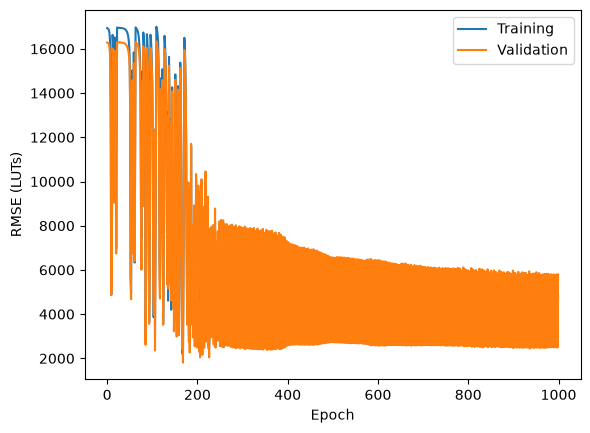

Final training RMSE: 4833.217492242353
Final validation RMSE: 5796.024243998296


In [ ]:
#Inspect learning over time
train_rmse_curve = np.sqrt(np.asarray(history["train_loss"]))
val_rmse_curve = np.sqrt(np.asarray(history["val_loss"]))

plt.plot(train_rmse_curve, label="Training")
plt.plot(val_rmse_curve, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("RMSE (LUTs)")
plt.legend()
plt.show()

print("Final training RMSE:", train_rmse_curve[-1])
print("Final validation RMSE:", val_rmse_curve[-1])

In [37]:
#Check that gradients and updates exist
probe = copy.deepcopy(model)
from circuitcost.train import mse_gradient


predictions = probe.forward(Xtr[:8])
gradient = mse_gradient(ytr[:8], predictions)
probe.backward(gradient)

dense_layers = [
    layer for layer in probe.layers
    if hasattr(layer, "weights")
]

for number, layer in enumerate(dense_layers, start=1):
    print(
        f"Layer {number}:",
        "weight-gradient size =", np.linalg.norm(layer.dweights),
        "gradients finite =", np.isfinite(layer.dweights).all(),
    )

before = dense_layers[0].weights.copy()
probe.step(learning_rate=1e-6)

print(
    "First-layer weight change:",
    np.linalg.norm(dense_layers[0].weights - before),
)

Layer 1: weight-gradient size = 14738963.697713973 gradients finite = True
Layer 2: weight-gradient size = 11905076.094778419 gradients finite = True
Layer 3: weight-gradient size = 11793724.562899943 gradients finite = True
First-layer weight change: 14.738963697713972


In [38]:
#Comparing the update size with weight size
weight_norm = np.linalg.norm(before)

update_norm = np.linalg.norm(
    dense_layers[0].weights - before
)

relative_update = update_norm / (weight_norm + 1e-12)

print("Original weight norm:", weight_norm)
print("Update norm:", update_norm)
print(f"Relative update: {relative_update:.2%}")

Original weight norm: 56.17977918798824
Update norm: 14.738963697713972
Relative update: 26.24%


In [44]:
#Checking whether that update improved the loss
from circuitcost.train import mse_loss

xb = Xtr[:8]
yb = ytr[:8]

loss_before = mse_loss(yb, model.forward(xb))
loss_after = mse_loss(yb, probe.forward(xb))

print("Before update:", loss_before)
print("After update:", loss_after)

Before update: 54430383.02042696
After update: 3449236170.0739017


In [41]:
predictions = probe.forward(Xtr)
gradient = mse_gradient(ytr, predictions)

In [45]:
#Training session 2
np.random.seed(42)

longer_model = NeuralNetworks(
    n_inputs=X_train_scaled.shape[1]
)

longer_history = train_model(
    longer_model,
    X_train_scaled,
    y_train,
    X_val_scaled,
    y_val,
    epochs=3000,
    learning_rate=0.000001,
)


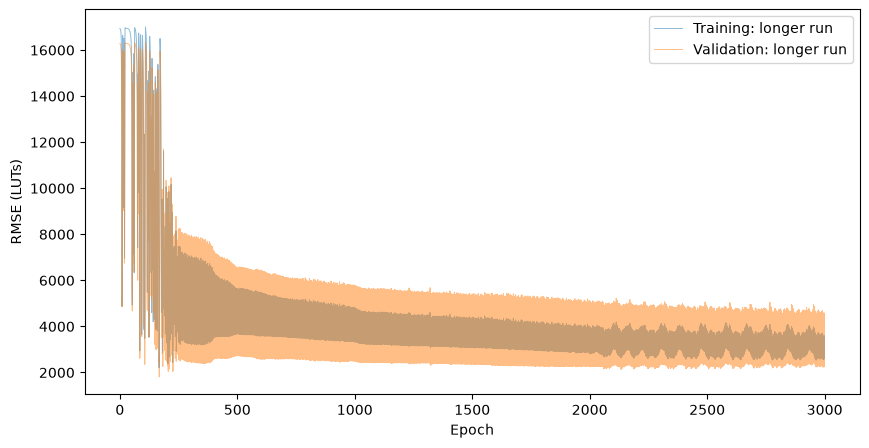

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(
    np.sqrt(longer_history["train_loss"]),
    label="Training: longer run",
    color="tab:blue",
    alpha=0.5,
    linewidth=0.7,
)

plt.plot(
    np.sqrt(longer_history["val_loss"]),
    label="Validation: longer run",
    color="tab:orange",
    alpha=0.5,
    linewidth=0.7,
)

plt.xlabel("Epoch")
plt.ylabel("RMSE (LUTs)")
plt.legend()
plt.show()

In [49]:
train_mse = longer_history["train_loss"][-1]
val_mse = longer_history["val_loss"][-1]

print(f"Final training MSE:   {train_mse:.2f}")
print(f"Final validation MSE: {val_mse:.2f}")

print(f"Final training RMSE:   {np.sqrt(train_mse):.2f} LUTs")
print(f"Final validation RMSE: {np.sqrt(val_mse):.2f} LUTs")

Final training MSE:   12898315.67
Final validation MSE: 20496203.27
Final training RMSE:   3591.42 LUTs
Final validation RMSE: 4527.27 LUTs


In [50]:
best_index = np.argmin(longer_history["val_loss"])
best_mse = longer_history["val_loss"][best_index]

print("Best validation epoch:", best_index + 1)
print(f"Best validation RMSE: {np.sqrt(best_mse):.2f} LUTs")

Best validation epoch: 169
Best validation RMSE: 1804.11 LUTs
